# **05: LSTM applicability pipeline**

### **Goals**

Validate LSTM's usage.

### **Challenges**

### **Stack**

# Download

In [ ]:
!pip install wntr -q
!pip install torch-geometric -q

# Imports

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/Academic Research')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import wntr
import wntr.graphics as wntr_graphics
import networkx as nx
import os

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from data_use import (
    normalizar_residuo, taxa_exceedance, calcular_residuo
)

from data_access import (
    get_all, leak_info
)

from data_menagement import (
    process_scenario_data
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 05_1: `error_normalizado` + 365 dias
## Data preparation

In [ ]:
def map_graph(scenarios):
    # carregar topologia
    wn = wntr.network.WaterNetworkModel(scenarios[146]['inp'])
    G = wn.to_graph().to_undirected()

    # lista em ordem fixa de nós
    list_nodes = sorted(wn.junction_name_list, key=int)
    nodes_index = {node: i for i, node in enumerate(list_nodes)} # enumerate devolve par (posição, valor) pra cada elemento de uma lista

    print(list_nodes)
    print(nodes_index)

    return G, list_nodes, nodes_index

In [ ]:
# sem grafos, sem classificação
def build_lstm_data(scenarios, list_nodes, days, window_size, step):
    list_x = []
    list_y = []

    for n, item in scenarios.items():
        dfs_nodes, leak_intervals, total_steps = process_scenario_data(item, list_nodes, days)

        for t_init in range(0, total_steps - (2 * window_size) + 1, step):
            t_end = t_init + window_size

            for node in list_nodes:
                df_node = dfs_nodes[node]

                # janela atual
                x = df_node['error_normalizado'].iloc[t_init:t_end].values

                # próxima janela
                y = df_node['error_normalizado'].iloc[t_end:t_end + window_size].values

                if len(x) < window_size or len(y) < window_size:
                    continue

                # formatação dos tensores
                x_tensor = torch.tensor(x, dtype=torch.float).unsqueeze(-1)
                y_tensor = torch.tensor(y, dtype=torch.float)

                list_x.append(x_tensor)
                list_y.append(y_tensor)

    return list_x, list_y

**Por que uma lista de tensores?**

Questão de manuseio de memória.
O objetivo, no final, é unir tudo em uma lista leve com loop para que só no fim seja convertido para tensor.

Em uma regressão normal, apenas com PyTorch clássico, uma rede neural não aceita objetos espaciais. Dito isso, o `DataLoader` clássico exige que um único e grande tensor 3D seja entregue com toda a base de dados, em vez de milhares tensores soltos.

Listas do Python, colunas do Pandas e arrays do NumPy rodam exclusivamente na CPU do computador, uma por vez. O Tensor foi criado para ser rodado em GPU, que realiza várias atividades em paralelo. Para uma rede neural realizar milhões de multiplicações de matrizes, o dado precisa estar em formato Tensor para que a GPU processe.

Além disso, o PyTorch registra exatamente quais operações geraram um número em qualquer cálculo. Os tensores mantêm o histórico das derivadas parciais na memória. É esse histórico que permite ao PyTorch voltar no tempo e calcular o quanto cada peso do modelo errou.

In [ ]:
scenarios_train = get_all('noLeak')
    # path
    # inp
    # info
    # leaks
    # pressures

G, list_nodes, nodes_index = map_graph(scenarios_train)

list_x, list_y = build_lstm_data(scenarios_train, list_nodes, days=14, window_size=48, step=48)

X_tensor = torch.stack(list_x)
Y_tensor = torch.stack(list_y)

dataset = TensorDataset(X_tensor, Y_tensor)
train_loader = DataLoader(dataset, batch_size=32, shuffle=True)

['2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32']
{'2': 0, '3': 1, '4': 2, '5': 3, '6': 4, '7': 5, '8': 6, '9': 7, '10': 8, '11': 9, '12': 10, '13': 11, '14': 12, '15': 13, '16': 14, '17': 15, '18': 16, '19': 17, '20': 18, '21': 19, '22': 20, '23': 21, '24': 22, '25': 23, '26': 24, '27': 25, '28': 26, '29': 27, '30': 28, '31': 29, '32': 30}


## Train

In [ ]:
class LSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, output_size=48):
        super().__init__()

        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True)

        # camada de output -> pega o vetor de memória final da LSTM e mapeia em 48 números físicos reais
        # atua como decoder para alinhas o output com o formato desejado
        self.linear = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x = [batch_size, 48, 1]
        out, (h_n, c_n) = self.lstm(x)

        pred_lstm = out[:, -1, :]
        pred_linear = self.linear(pred_lstm)

        return pred_linear

In [ ]:
len(train_loader.dataset)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Rodando hardware em: {device}")

Rodando hardware em: cpu


In [ ]:
model = LSTM(input_size=1, hidden_size=64, output_size=48)
optim = torch.optim.Adam(model.parameters(), lr=0.001)

criteria = nn.MSELoss()
model.train()

# train loop
epochs = 100
for epoch in range(epochs):
    total_loss = 0

    for batch_x, batch_y in train_loader:
        optim.zero_grad()

        output = model(batch_x)
        loss = criteria(output, batch_y)

        loss.backward()
        optim.step()

        total_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        mean_loss = total_loss / len(train_loader)
        print(f"Época {epoch+1}/{epochs}, Perda Média (MSE): {mean_loss:.4f}")

Época 10/100, Perda Média (MSE): 0.0516
Época 20/100, Perda Média (MSE): 0.0484
Época 30/100, Perda Média (MSE): 0.0463
Época 40/100, Perda Média (MSE): 0.0449
Época 50/100, Perda Média (MSE): 0.0415
Época 60/100, Perda Média (MSE): 0.0395
Época 70/100, Perda Média (MSE): 0.0375
Época 80/100, Perda Média (MSE): 0.0357
Época 90/100, Perda Média (MSE): 0.0337
Época 100/100, Perda Média (MSE): 0.0323


**Por que `loss.backward()`?**

É o momento que o PyTorch pega a loss final e passa por toda a rede neural derivando cada peso e cada viés da LSTM e da camada Linear.

Na prática, é o mapeamento da relevância de cada unit e da camada Linear no erro, e o resultado são os gradientes salvos na memória, então quem errou o que e com que intensidade, mas sem mudar os pesos.

**Por que `optim.step()`?**

Olha para os gradientes e atualiza pesos e viéses originais da rede. Aqui é o momento que a `lr` afeta.

## Eval

In [ ]:
model = model.to(device)
model.eval()

# pegar exemplo qualquer
with torch.no_grad():
  x_ex, y_real = dataset[0]
  x_in = x_ex.unsqueeze(0).to(device) # rede exige dimension extra [48, 1] -> [1, 48, 1]

  y_pred = model(x_in) # rede prevê a janela inteira

  # volta para a CPU e converte para numpy
  y_pred = y_pred.squeeze(0).cpu().numpy()
  y_real = y_real.numpy()

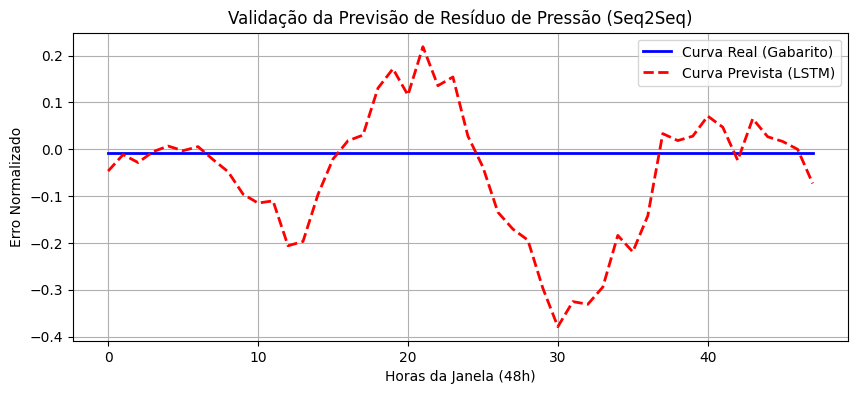

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(y_real, label="Curva Real (Gabarito)", color="blue", linewidth=2)
plt.plot(y_pred, label="Curva Prevista (LSTM)", color="red", linestyle="--", linewidth=2)
plt.title("Validação da Previsão de Resíduo de Pressão (Seq2Seq)")
plt.xlabel("Horas da Janela (48h)")
plt.ylabel("Erro Normalizado")
plt.legend()
plt.grid(True)
plt.show()

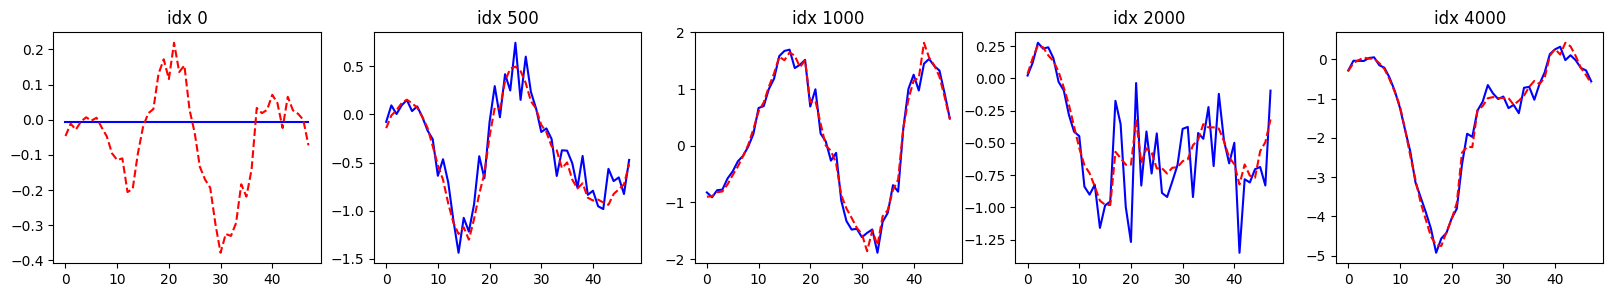

In [ ]:
with torch.no_grad():
    fig, axs = plt.subplots(1, 5, figsize=(20,3))
    for i, idx in enumerate([0, 500, 1000, 2000, 4000]):  # espalha pelo dataset
        x_ex, y_real = dataset[idx]
        x_in = x_ex.unsqueeze(0).to(device)
        y_pred = model(x_in).squeeze(0).cpu().numpy()

        axs[i].plot(y_real.numpy(), color="blue")
        axs[i].plot(y_pred, color="red", linestyle="--")
        axs[i].set_title(f"idx {idx}")
    plt.show()

**Por que idx 0 está com target = 0?**

O desenvolvimento da função `calcular_residuo` para mapear os desvios-padrão entre a média de 14 dias e o valor da pressão naquele timestep, mas o cálculo da média móvel só aceita resultados com `min_periods=3`.

A primeira janela cobre exatamente os primeiros dias da série, então o 0 não é sinal real, é um preenchimento criado por mim.

O modelo não tem capacidade de acertar sem o target, mas prevê de acordo com o padrão sazonal que aprendeu durante o treinamento.

**Por que é necessário fazer alguma coisa?**

Isso não é uma contaminação que destrói todo o dataset de treino, mas ensina ao modelo uma associação x->y em um mesmo pedaço em cada nó de cada cenário e isso faz de qualquer avaliação dessas janelas específicas enganosas.

# Conclusões

## **Problema**: Por que `idx[0]-idx[30]` = flat?

Depois de tentar o problema, a primeira suposição estava relacionada à forma que eu escolhi lidar com os primeiros dias do dataset, nos quais apenas pressões a partir do 3° dia poderiam participar do cálculo de média móvel, enquanto os dois primeiros dias ficariam com desvios-padrão = 0.

Para tentar resolver isso, estabeleci que o início do range seria em `3 * window_size`, para que os 3 primeiros dias fossem pulados no treinamento.

Essa decisão precisa ser analisada quanto validade a longo prazo, porém optei por tirar para que não houvesse interferência do `fillna`.

##

# 05_2: `error_normalizado` + 362 dias

## Data preparation

In [ ]:
def fixed_build_lstm_data(scenarios, list_nodes, days, window_size, step):
    list_x = []
    list_y = []

    for n, item in scenarios.items():
        dfs_nodes, leak_intervals, total_steps = process_scenario_data(item, list_nodes, days)

        for t_init in range(3 * window_size, total_steps - ((2 * window_size) + 1), step):
            t_end = t_init + window_size

            for node in list_nodes:
                df_node = dfs_nodes[node]

                # janela atual
                x = df_node['error_normalizado'].iloc[t_init:t_end].values

                # próxima janela
                y = df_node['error_normalizado'].iloc[t_end:t_end + window_size].values

                if len(x) < window_size or len(y) < window_size:
                    continue

                # formatação dos tensores
                x_tensor = torch.tensor(x, dtype=torch.float).unsqueeze(-1)
                y_tensor = torch.tensor(y, dtype=torch.float)

                list_x.append(x_tensor)
                list_y.append(y_tensor)

    return list_x, list_y

In [ ]:
scenarios_train = get_all('noLeak')
    # path
    # inp
    # info
    # leaks
    # pressures

G, list_nodes, nodes_index = map_graph(scenarios_train)

fixed_list_x, fixed_list_y = fixed_build_lstm_data(scenarios_train, list_nodes, days=14, window_size=48, step=48)

fixed_X_tensor = torch.stack(fixed_list_x)
fixed_Y_tensor = torch.stack(fixed_list_y)

dataset_fixed = TensorDataset(fixed_X_tensor, fixed_Y_tensor)
train_loader_fixed = DataLoader(dataset_fixed, batch_size=32, shuffle=True)

['2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32']
{'2': 0, '3': 1, '4': 2, '5': 3, '6': 4, '7': 5, '8': 6, '9': 7, '10': 8, '11': 9, '12': 10, '13': 11, '14': 12, '15': 13, '16': 14, '17': 15, '18': 16, '19': 17, '20': 18, '21': 19, '22': 20, '23': 21, '24': 22, '25': 23, '26': 24, '27': 25, '28': 26, '29': 27, '30': 28, '31': 29, '32': 30}


## Train

In [ ]:
model = LSTM(input_size=1, hidden_size=64, output_size=48)
optim = torch.optim.Adam(model.parameters(), lr=0.001)

criteria = nn.MSELoss()
model.train()

# train loop
epochs = 100
for epoch in range(epochs):
    total_loss = 0

    for batch_x_fixed, batch_y_fixed in train_loader_fixed:
        optim.zero_grad()

        output_fixed = model(batch_x_fixed)
        loss = criteria(output_fixed, batch_y_fixed)

        loss.backward()
        optim.step()

        total_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        mean_loss = total_loss / len(train_loader_fixed)
        print(f"Época {epoch+1}/{epochs}, Perda Média (MSE): {mean_loss:.4f}")

Época 10/100, Perda Média (MSE): 0.0529
Época 20/100, Perda Média (MSE): 0.0490
Época 30/100, Perda Média (MSE): 0.0529
Época 40/100, Perda Média (MSE): 0.0459
Época 50/100, Perda Média (MSE): 0.0435
Época 60/100, Perda Média (MSE): 0.0414
Época 70/100, Perda Média (MSE): 0.0390
Época 80/100, Perda Média (MSE): 0.0369
Época 90/100, Perda Média (MSE): 0.0350
Época 100/100, Perda Média (MSE): 0.0337


## Eval

In [ ]:
model = model.to(device)
model.eval()

# pegar exemplo qualquer
with torch.no_grad():
  x_ex_fixed, y_real_fixed = dataset_fixed[0]
  x_in_fixed = x_ex_fixed.unsqueeze(0).to(device) # rede exige dimension extra [48, 1] -> [1, 48, 1]

  y_pred_fixed = model(x_in_fixed) # rede prevê a janela inteira

  # volta para a CPU e converte para numpy
  y_pred_fixed = y_pred_fixed.squeeze(0).cpu().numpy()
  y_real_fixed = y_real_fixed.numpy()

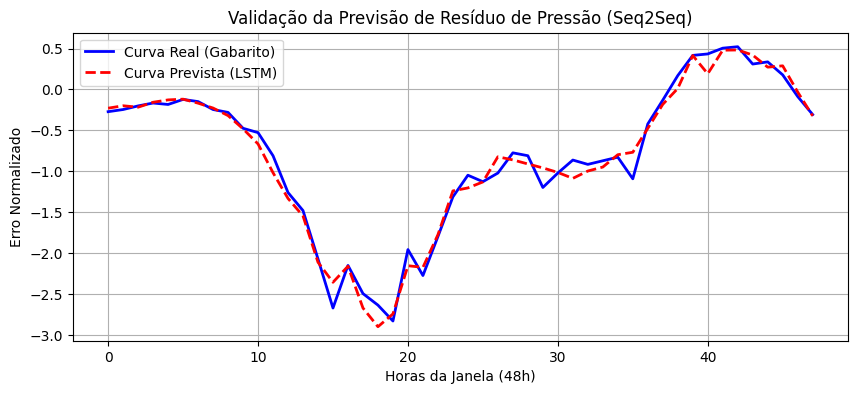

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(y_real_fixed, label="Curva Real (Gabarito)", color="blue", linewidth=2)
plt.plot(y_pred_fixed, label="Curva Prevista (LSTM)", color="red", linestyle="--", linewidth=2)
plt.title("Validação da Previsão de Resíduo de Pressão (Seq2Seq)")
plt.xlabel("Horas da Janela (48h)")
plt.ylabel("Erro Normalizado")
plt.legend()
plt.grid(True)
plt.show()

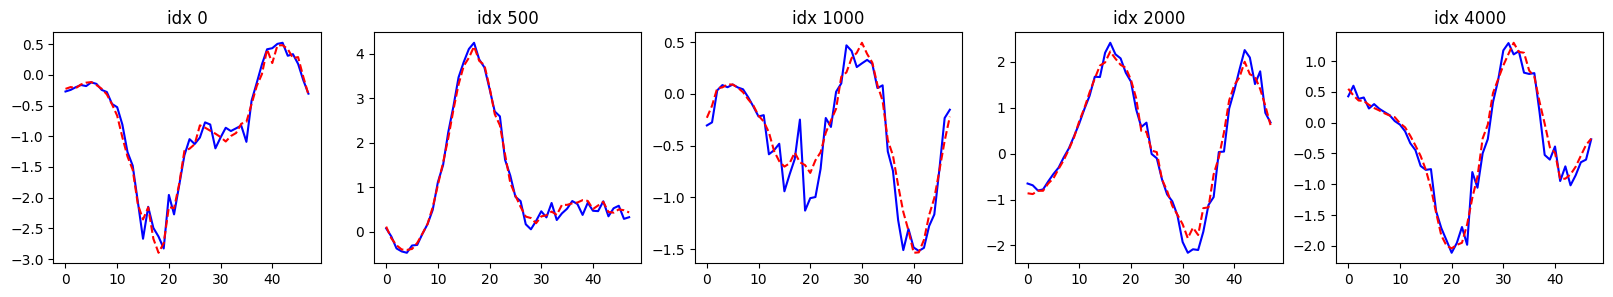

In [ ]:
with torch.no_grad():
    fig, axs = plt.subplots(1, 5, figsize=(20,3))
    for i, idx in enumerate([0, 500, 1000, 2000, 4000]):  # espalha pelo dataset
        x_ex_fixed, y_real_fixed = dataset_fixed[idx]
        x_in_fixed = x_ex_fixed.unsqueeze(0).to(device)
        y_pred_fixed = model(x_in_fixed).squeeze(0).cpu().numpy()

        axs[i].plot(y_real_fixed.numpy(), color="blue")
        axs[i].plot(y_pred_fixed, color="red", linestyle="--")
        axs[i].set_title(f"idx {idx}")
    plt.show()

# 05_3: First test with leak scenary
The approach used is gonna be the second one.

In [ ]:
def meta_build_lstm_data(scenarios, list_nodes, days, window_size, step):
    list_x = []
    list_y = []
    meta = []

    for n, item in scenarios.items():
        dfs_nodes, leak_intervals, total_steps = process_scenario_data(item, list_nodes, days)

        for t_init in range(3 * window_size, total_steps - ((2 * window_size) + 1), step):
            t_end = t_init + window_size

            for node in list_nodes:
                df_node = dfs_nodes[node]

                # janela atual
                x = df_node['error_normalizado'].iloc[t_init:t_end].values

                # próxima janela
                y = df_node['error_normalizado'].iloc[t_end:t_end + window_size].values

                if len(x) < window_size or len(y) < window_size:
                    continue

                # formatação dos tensores
                x_tensor = torch.tensor(x, dtype=torch.float).unsqueeze(-1)
                y_tensor = torch.tensor(y, dtype=torch.float)

                list_x.append(x_tensor)
                list_y.append(y_tensor)

                meta.append((n, t_init, node))

    return list_x, list_y, meta

In [ ]:
scenarios_test = get_all('leak')
G, list_nodes, nodes_index = map_graph(scenarios_train)

test_list_x, test_list_y, meta = meta_build_lstm_data(scenarios_test, list_nodes, days=14, window_size=48, step=48)

test_X_tensor = torch.stack(test_list_x)
test_Y_tensor = torch.stack(test_list_y)
dataset_test = TensorDataset(test_X_tensor, test_Y_tensor)

model.eval()

['2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32']
{'2': 0, '3': 1, '4': 2, '5': 3, '6': 4, '7': 5, '8': 6, '9': 7, '10': 8, '11': 9, '12': 10, '13': 11, '14': 12, '15': 13, '16': 14, '17': 15, '18': 16, '19': 17, '20': 18, '21': 19, '22': 20, '23': 21, '24': 22, '25': 23, '26': 24, '27': 25, '28': 26, '29': 27, '30': 28, '31': 29, '32': 30}


LSTM(
  (lstm): LSTM(1, 64, batch_first=True)
  (linear): Linear(in_features=64, out_features=48, bias=True)
)

In [ ]:
idx = 5651
with torch.no_grad():
  x_ex_test, y_real_test = dataset_test[idx]
  x_in_test = x_ex_test.unsqueeze(0).to(device)

  y_pred_test = model(x_in_test)

  # converte para cpu para matplotlib
  y_pred_test = y_pred_test.squeeze(0).cpu().numpy()
  y_real_test = y_real_test.numpy()
  x_real_test = x_in_test.squeeze().cpu().numpy()

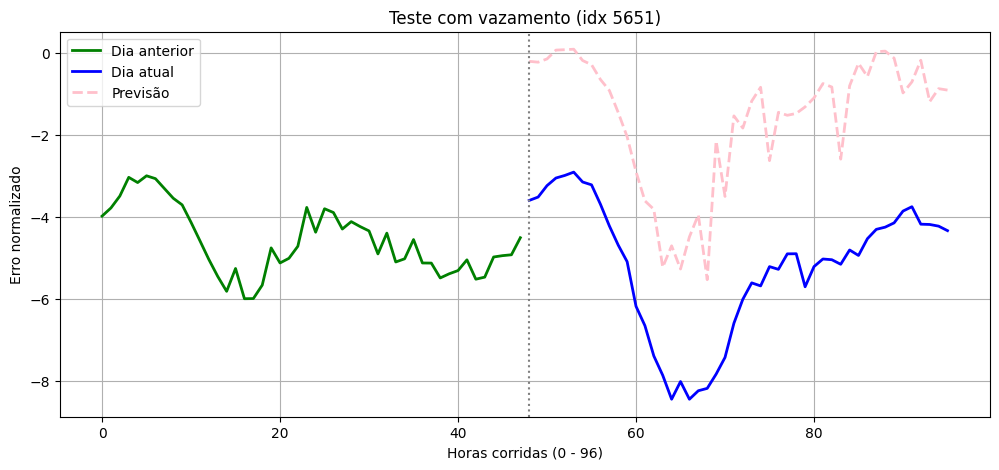

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(range(0, 48), x_real_test, label="Dia anterior", color='green', linewidth=2)
plt.plot(range(48, 96), y_real_test, label= "Dia atual", color='blue', linewidth=2)
plt.plot(range(48, 96), y_pred_test, label="Previsão", color='pink', linestyle="--", linewidth=2)

plt.axvline(x=48, color='gray', linestyle=':')
plt.title(f"Teste com vazamento (idx {idx})")
plt.xlabel("Horas corridas (0 - 96)")
plt.ylabel("Erro normalizado")

plt.legend()
plt.grid(True)
plt.show()

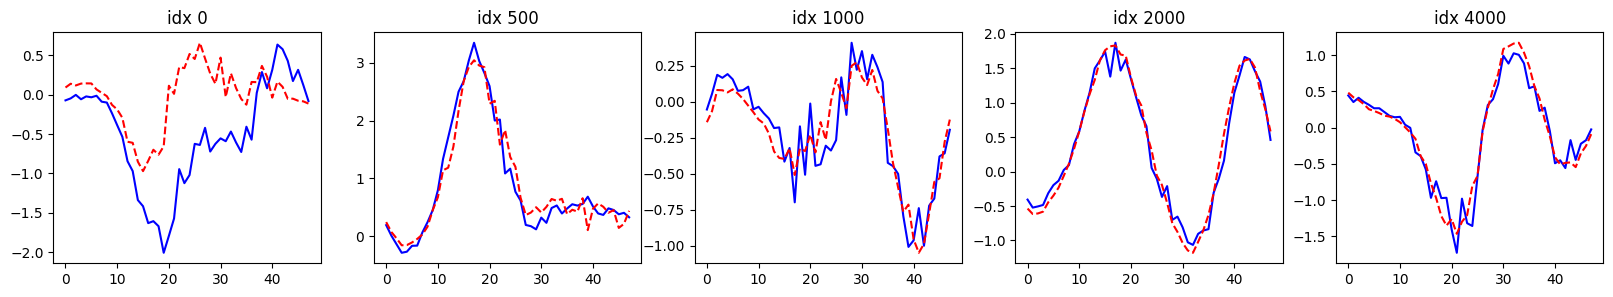

In [ ]:
with torch.no_grad():
    fig, axs = plt.subplots(1, 5, figsize=(20,3))
    for i, idx in enumerate([0, 500, 1000, 2000, 4000]):  # espalha pelo dataset
        x_ex_test, y_real_test = dataset_test[idx]
        x_in_test = x_ex_test.unsqueeze(0).to(device)
        y_pred_test = model(x_in_test).squeeze(0).cpu().numpy()

        axs[i].plot(y_real_test.numpy(), color="blue")
        axs[i].plot(y_pred_test, color="red", linestyle="--")
        axs[i].set_title(f"idx {idx}")
    plt.show()

# 05_4: Normal pressures

## Data preparation

In [ ]:
def normalize_pressure(df):
  mean = df['Value'].mean()
  std = df['Value'].std()
  df['norm_pressure'] = ((df['Value'] - mean) / (std + 1e-8))

In [ ]:
def scenario_data(item, list_nodes):
    list_data = []

    leak_intervals = {}
    earliest_start = float('inf')
    if len(item['leaks']) > 0:
        for leak in item['leaks']:
            start, end, peak = leak_info(item['path'], leak)
            leak_intervals[leak] = (start, end)

            # guarda o menor start de todos
            if start < earliest_start:
                earliest_start = start

    # quantos instantes tem?
    ex_df = pd.read_csv(os.path.join(item['path'], 'Pressures', f'Node_{list_nodes[0]}.csv'))
    total_steps = len(ex_df)

    dfs_nodes = {}

    for node in list_nodes:
      node_path = os.path.join(item['path'], 'Pressures', f'Node_{node}.csv')
      df_node = pd.read_csv(node_path)

      dfs_nodes[node] = df_node

    return dfs_nodes, leak_intervals, total_steps

In [ ]:
def lstm_pressure_data(scenarios, list_nodes, window_size, step):
  list_x = []
  list_y = []
  meta = []

  for n, item in scenarios.items():
    dfs_nodes, leak_intervals, total_steps = scenario_data(item, list_nodes)

    for node in dfs_nodes:
      normalize_pressure(dfs_nodes[node])

    for t_init in range(0, total_steps - ((2 * window_size) + 1), step):
        t_end = t_init + window_size

        for node in list_nodes:
            df_node = dfs_nodes[node]

            # janela atual
            x = df_node['norm_pressure'].iloc[t_init:t_end].values

            # próxima janela
            y = df_node['norm_pressure'].iloc[t_end:t_end + window_size].values

            if len(x) < window_size or len(y) < window_size:
                continue

            # formatação dos tensores
            x_tensor = torch.tensor(x, dtype=torch.float).unsqueeze(-1)
            y_tensor = torch.tensor(y, dtype=torch.float)

            list_x.append(x_tensor)
            list_y.append(y_tensor)

            meta.append((n, t_init, node))

  return list_x, list_y, meta

In [ ]:
scenarios_norm = get_all('noLeak')
    # path
    # inp
    # info
    # leaks
    # pressures

G, list_nodes, nodes_index = map_graph(scenarios_train)

list_x_norm, list_y_norm, meta_norm = lstm_pressure_data(scenarios_norm, list_nodes, window_size=48, step=48)

X_tensor_norm = torch.stack(list_x_norm)
Y_tensor_norm = torch.stack(list_y_norm)

dataset_norm = TensorDataset(X_tensor_norm, Y_tensor_norm)
train_loader_norm = DataLoader(dataset_norm, batch_size=32, shuffle=True)

['2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32']
{'2': 0, '3': 1, '4': 2, '5': 3, '6': 4, '7': 5, '8': 6, '9': 7, '10': 8, '11': 9, '12': 10, '13': 11, '14': 12, '15': 13, '16': 14, '17': 15, '18': 16, '19': 17, '20': 18, '21': 19, '22': 20, '23': 21, '24': 22, '25': 23, '26': 24, '27': 25, '28': 26, '29': 27, '30': 28, '31': 29, '32': 30}


## Train

In [ ]:
model_norm = LSTM(input_size=1, hidden_size=64, output_size=48)
optim = torch.optim.Adam(model_norm.parameters(), lr=0.001)

criteria = nn.MSELoss()
model_norm.train()

# train loop
epochs = 100
for epoch in range(epochs):
    total_loss = 0

    for batch_x, batch_y in train_loader_norm:
        optim.zero_grad()

        output = model_norm(batch_x)
        loss = criteria(output, batch_y)

        loss.backward()
        optim.step()

        total_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        mean_loss = total_loss / len(train_loader_norm)
        print(f"Época {epoch+1}/{epochs}, Perda Média (MSE): {mean_loss:.4f}")

Época 10/100, Perda Média (MSE): 0.0032
Época 20/100, Perda Média (MSE): 0.0038
Época 30/100, Perda Média (MSE): 0.0027
Época 40/100, Perda Média (MSE): 0.0031
Época 50/100, Perda Média (MSE): 0.0026
Época 60/100, Perda Média (MSE): 0.0026
Época 70/100, Perda Média (MSE): 0.0028
Época 80/100, Perda Média (MSE): 0.0026
Época 90/100, Perda Média (MSE): 0.0039
Época 100/100, Perda Média (MSE): 0.0024


## Eval

In [ ]:
model_norm.to(device)
model_norm.eval()

with torch.no_grad():
  x_ex_norm, y_real_norm = dataset_norm[752]
  x_in_norm = x_ex_norm.unsqueeze(0).to(device) # [48, 1] -> [1, 48, 1]

  y_pred_norm = model_norm(x_in_norm)

  y_pred_norm = y_pred_norm.squeeze(0).cpu().numpy()
  y_real_norm = y_real_norm.numpy()

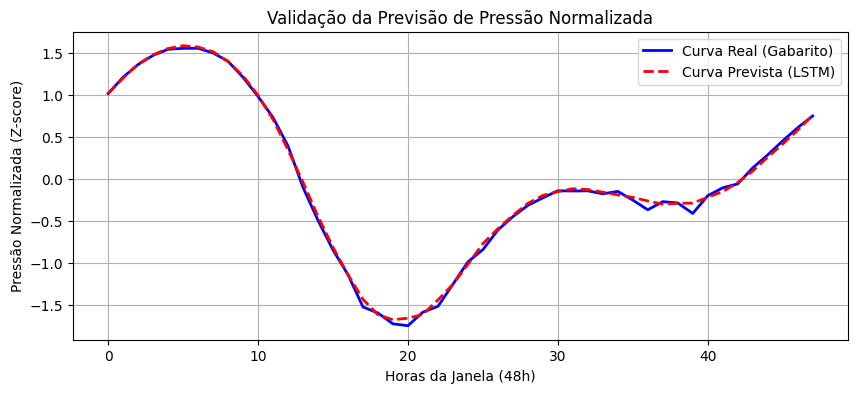

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(y_real_norm, label="Curva Real (Gabarito)", color="blue", linewidth=2)
plt.plot(y_pred_norm, label="Curva Prevista (LSTM)", color="red", linestyle="--", linewidth=2)
plt.title("Validação da Previsão de Pressão Normalizada")
plt.xlabel("Horas da Janela (48h)")
plt.ylabel("Pressão Normalizada (Z-score)")
plt.legend()
plt.grid(True)
plt.show()

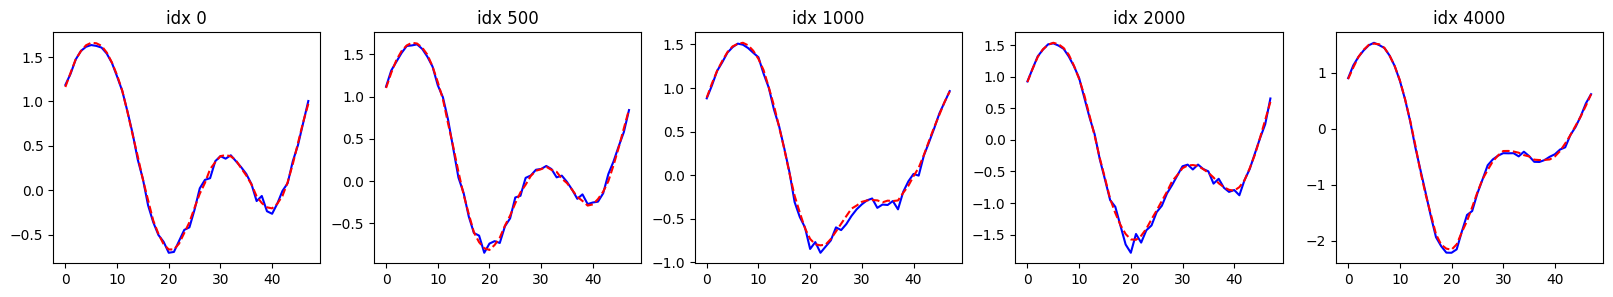

In [ ]:
with torch.no_grad():
    fig, axs = plt.subplots(1, 5, figsize=(20,3))
    for i, idx in enumerate([0, 500, 1000, 2000, 4000]):  # espalha pelo dataset
        x_ex_norm, y_real_norm = dataset_norm[idx]
        x_in_norm = x_ex_norm.unsqueeze(0).to(device)
        y_pred_norm = model_norm(x_in_norm).squeeze(0).cpu().numpy()

        axs[i].plot(y_real_norm.numpy(), color="blue")
        axs[i].plot(y_pred_norm, color="red", linestyle="--")
        axs[i].set_title(f"idx {idx}")
    plt.show()

# 05_5: Normal pressures with leak

In [ ]:
scenario_leak = get_all('leak')
G, list_nodes, nodes_index = map_graph(scenarios_train)

list_x_leak, list_y_leak, meta_leak = lstm_pressure_data(scenario_leak, list_nodes, window_size=48, step=48)

X_tensor_leak = torch.stack(list_x_leak)
Y_tensor_leak = torch.stack(list_y_leak)
dataset_leak = TensorDataset(X_tensor_leak, Y_tensor_leak)

model_norm.eval()

['2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32']
{'2': 0, '3': 1, '4': 2, '5': 3, '6': 4, '7': 5, '8': 6, '9': 7, '10': 8, '11': 9, '12': 10, '13': 11, '14': 12, '15': 13, '16': 14, '17': 15, '18': 16, '19': 17, '20': 18, '21': 19, '22': 20, '23': 21, '24': 22, '25': 23, '26': 24, '27': 25, '28': 26, '29': 27, '30': 28, '31': 29, '32': 30}


LSTM(
  (lstm): LSTM(1, 64, batch_first=True)
  (linear): Linear(in_features=64, out_features=48, bias=True)
)

In [ ]:
idx = 5651
with torch.no_grad():
  x_ex_leak, y_real_leak = dataset_leak[idx]
  x_in_leak = x_ex_leak.unsqueeze(0).to(device)

  y_pred_leak = model_norm(x_in_leak)

  # converte para cpu para matplotlib
  y_pred_leak = y_pred_leak.squeeze(0).cpu().numpy()
  y_real_leak = y_real_leak.numpy()
  x_real_leak = x_in_leak.squeeze().cpu().numpy()

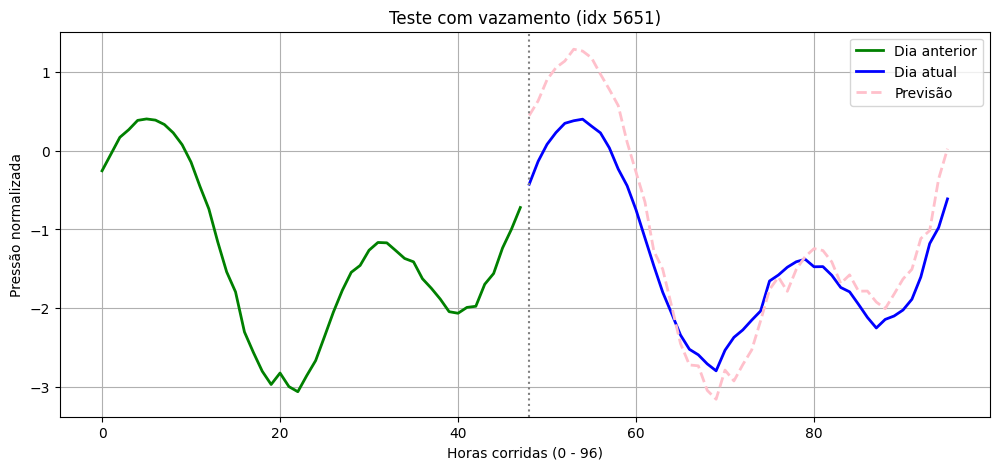

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(range(0, 48), x_real_leak, label="Dia anterior", color='green', linewidth=2)
plt.plot(range(48, 96), y_real_leak, label= "Dia atual", color='blue', linewidth=2)
plt.plot(range(48, 96), y_pred_leak, label="Previsão", color='pink', linestyle="--", linewidth=2)

plt.axvline(x=48, color='gray', linestyle=':')
plt.title(f"Teste com vazamento (idx {idx})")
plt.xlabel("Horas corridas (0 - 96)")
plt.ylabel("Pressão normalizada")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(meta_leak[5555])  # (cenário, t_init, nó) que a imagem 1 realmente representa

wanted_idx = 0

for idx, (sce, init, node) in enumerate(meta_leak):
  if node == '11' and init == 8736:
    wanted_idx = idx

print(wanted_idx)

(288, 8592, '8')
5651


# Regression Metrics
> Uma rede LSTM consegue capturar a volatilidade e as anomalias do sistema sozinha apenas com pressão escalonada, ou ela precisa de feature engineering explícita?

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def eval_modeling(modeling, dataloader, name):
  modeling.eval()

  all_pred = []
  all_real = []

  with torch.no_grad():
    for x_batch, y_batch in dataloader:
      x_batch = x_batch.to(device)
      preds = modeling(x_batch)

      # cpu
      all_pred.append(preds.cpu().numpy())
      all_real.appen(y_batch.numpy())

  all_pred = np.concatenate(all_pred).flatten()
  all_real = np.concatenate(all_real).flatten()

  mae = mean_absolute_error(all_real, all_pred)
  rmse = np.sqrt(mean_squared_error(all_real, all_pred))
  r2 = r2_score(all_real, all_pred)

  print(f"--- Resultados Globais: {name} ---")
  print(f"MAE:  {mae:.4f}")
  print(f"RMSE: {rmse:.4f}")
  print(f"R²:   {r2:.4f}\n")

  return mae, rmse, r2_score


In [ ]:
def plot_comparation(model_feat, model_norm, dataset, dataset_norm, idx):
  model_feat.to(device)
  model_norm.to(device)
  model_feat.eval()
  model_norm.eval()

# Extrair a mesma janela temporal de ambos os datasets
  x_feat, y_real = dataset_feat[idx]
  x_norm, _ = dataset_norm[idx]

  with torch.no_grad():
      # Adicionar dimensão do batch e inferir
      pred_feat = model_feat(x_feat.unsqueeze(0).to(device)).squeeze().cpu().numpy()
      pred_norm = model_norm(x_norm.unsqueeze(0).to(device)).squeeze().cpu().numpy()

  y_real = y_real.squeeze().numpy()

  # Montagem do Gráfico
  plt.figure(figsize=(14, 6))
  plt.plot(y_real, label='Real (Resíduo de Pressão)', color='black', linewidth=2.5)
  plt.plot(pred_feat, label='Model (Features: Desvio Padrão)', color='red', linestyle='--', linewidth=2)
  plt.plot(pred_norm, label='Model Norm (Z-score Apenas)', color='blue', linestyle='-.', linewidth=2)

  plt.title(f"Comparação de Modelos LSTM - Janela {idx}", fontsize=14)
  plt.xlabel("Tempo (Horas / Timesteps)", fontsize=12)
  plt.ylabel("Variação de Pressão Normalizada", fontsize=12)
  plt.legend(fontsize=11)
  plt.grid(True, linestyle=':', alpha=0.7)
  plt.tight_layout()
  plt.show()

In [ ]:
eval_modeling(model, train_loader_fixed, "Modelo com Eng. de Features (Desvio Padrão)")
eval_modeling(model_norm, train_loader_norm, "Modelo Baseline (Z-Score)")

# Escolha um 'indice' onde você sabe que há um pico de vazamento para ver como eles se comportam
idx = 150
plot_comparation(model, model_norm, dataset, dataset_norm, idx)

AttributeError: 'list' object has no attribute 'appen'